# Allen Brain Atlas Aging Dementia and Traumatic Brain Injury Tissue Sample Gene Expression Profiles

This notebook contains the script used to process the Allen Brain Atlas Aging Dementia and TBI Tissue Sample Gene Expression Profiles dataset for Harmonizome. The data and metadata for tissue samples were downloaded from the Aging, Dementia, and TBI Study [portal](https://aging.brain-map.org/).

The unnormalized FPKM values were log-transformed, quantile-normalized, and z-scores were calculated for each gene relative to expression levels in other samples. Gene-tissue sample associations with |z|≥2 were kept to yield 312858 associations between 18548 and 377 samples.

In [48]:
import pandas as pd
import datetime
import math
import matplotlib.pyplot as plt
import numpy as np
import os
import re
import requests
import scipy.spatial.distance as dist
import seaborn as sns
import sys
import json
import scanpy as sc
from tqdm import tqdm
from maayanlab_bioinformatics.normalization import quantile_normalize
from maayanlab_bioinformatics.dge import characteristic_direction
from urllib.request import urlretrieve

# UMAP
from sklearn.feature_extraction.text import TfidfVectorizer
import anndata
from collections import OrderedDict

# Bokeh
from bokeh.io import output_notebook
from bokeh.plotting import figure, show, save, output_file
from bokeh.models import HoverTool, ColumnDataSource
from bokeh.palettes import Category20
output_notebook()

from IPython.display import display, HTML, Markdown
sys.setrecursionlimit(100000)

import pyarrow.feather as feather
from scipy.stats import rankdata, zscore

Loading BokehJS ...

## Load and Pre-Process Data

In [49]:
sample_df = pd.read_csv('gene_expression_matrix_2016-03-03/columns-samples.csv')
donor_df = pd.read_csv('DonorInformation.csv')
sample_df = pd.merge(sample_df, donor_df, on='donor_id')
sample_df

,rnaseq_profile_id,donor_id,donor_name,specimen_id,specimen_name,rna_well_id,polygon_id,structure_id,structure_acronym,structure_color,...,num_tbi_w_loc,dsm_iv_clinical_diagnosis,control_set,nincds_arda_diagnosis,ever_tbi_w_loc,race,hispanic,act_demented,braak,nia_reagan
0,488395315,309335467,H14.09.030,309357843,H14.09.030.TCx.01,395325172,320817998,10235,TCx,#ebbfd0,...,0,No Dementia,3,No Dementia,N,White,Not Hispanic,No Dementia,3,2
1,496100352,309335467,H14.09.030,309357840,H14.09.030.PCx.01,395325168,320965916,10557,FWM,#f2f1f0,...,0,No Dementia,3,No Dementia,N,White,Not Hispanic,No Dementia,3,2
2,496100381,309335467,H14.09.030,309357837,H14.09.030.HIP.01,395325166,320817993,10294,HIP,#bfb5d5,...,0,No Dementia,3,No Dementia,N,White,Not Hispanic,No Dementia,3,2
3,496100386,309335467,H14.09.030,309357840,H14.09.030.PCx.01,395325170,320965914,10208,PCx,#f0dabe,...,0,No Dementia,3,No Dementia,N,White,Not Hispanic,No Dementia,3,2
4,496100277,309335441,H14.09.004,309357624,H14.09.004.PCx.01,320630866,310967169,10557,FWM,#f2f1f0,...,0,No Dementia,14,No Dementia,N,White,Not Hispanic,No Dementia,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
372,496100663,467056405,H15.09.106,467179095,H15.09.106.TCx.01,482655846,480365137,10235,TCx,#ebbfd0,...,0,No Dementia,53,No Dementia,N,White,Not Hispanic,No Dementia,2,1
373,496100661,467056391,H15.09.103,467179068,H15.09.103.PCx.01,482655824,480363829,10208,PCx,#f0dabe,...,1,No Dementia,52,No Dementia,Y,White,Not Hispanic,No Dementia,4,0
374,496100667,467056391,H15.09.103,467179071,H15.09.103.TCx.01,482655826,480366830,10235,TCx,#ebbfd0,...,1,No Dementia,52,No Dementia,Y,White,Not Hispanic,No Dementia,4,0
375,496100669,467056391,H15.09.103,467179068,H15.09.103.PCx.01,482655822,480363830,10557,FWM,#f2f1f0,...,1,No Dementia,52,No Dementia,Y,White,Not Hispanic,No Dementia,4,0


In [50]:
gene_df = pd.read_csv('gene_expression_matrix_2016-03-03/rows-genes.csv', index_col=0)
gene_mapping = gene_df['gene_symbol'].to_dict()
gene_df

,chromosome,gene_entrez_id,gene_symbol,gene_name
gene_id,,,,
499304660,1,100287102,DDX11L1,DEAD/H (Asp-Glu-Ala-Asp/His) box helicase 11 l...
499304661,1,653635,WASH7P,WAS protein family homolog 7 pseudogene
499304662,1,102466751,MIR6859-1,microRNA 6859-1
499304663,1,100302278,MIR1302-2,microRNA 1302-2
499304664,1,645520,FAM138A,"family with sequence similarity 138, member A"
...,...,...,...,...
499355059,MT,4541,ND6,NADH dehydrogenase subunit 6
499355060,MT,4556,TRNE,tRNA-Glu
499355061,MT,4519,CYTB,cytochrome b


In [95]:
sample_descs = sample_df.copy().set_index('rnaseq_profile_id')
sample_descs['nincds_arda_diagnosis'] = sample_descs['nincds_arda_diagnosis'].map({
    "No Dementia":"no dementia",
    "Possible Alzheimer'S Disease":"possible Alzheimer's disease",
    "Probable Alzheimer'S Disease":"probable Alzheimer's disease",
    "Dementia, Type Unknown":"dementia"
})

sample_names = sample_descs.apply(
    lambda x: f"""{x.name}_{x["structure_acronym"]}_{x["nincds_arda_diagnosis"]}_{x["ever_tbi_w_loc"].replace("Y", "TBI").replace("N", "no TBI")}_{x["age"]}_{x["sex"]}""",
    axis=1,
).to_dict()

sample_descs = sample_descs.apply(
    lambda x: f"""{x["structure_name"].capitalize()} tissue sample from donor with {x["nincds_arda_diagnosis"]}, {x["ever_tbi_w_loc"].replace("Y", "TBI").replace("N", "no TBI")}, {x["age"]} years, {x["sex"].replace("M","male").replace("F","female")}""",
    axis=1,
).to_dict()

In [4]:
gene_info = pd.read_csv('../../tables/Homo_sapiens.gene_info.gz', compression='gzip', sep='\t')
gene_info = gene_info[(gene_info['#tax_id']==9606) & (gene_info['type_of_gene']=='protein-coding')]
gene_info['Symbol'] = gene_info['Symbol'].str.upper()
symbols = set(gene_info['Symbol'])
geneids = gene_info.set_index('Symbol')['GeneID'].to_dict()
synonyms = gene_info.copy()
synonyms['Synonyms'] = synonyms.apply(lambda x: x['Synonyms'].upper().split('|') + [x['Symbol']], axis=1)
synonyms = synonyms.explode('Synonyms')
synonyms['Synonyms'] = synonyms['Synonyms'].str.upper()
synonyms = synonyms[synonyms['Synonyms']!='-']
synonyms = synonyms.set_index('Synonyms')['Symbol'].to_dict()

In [67]:
expr_df = pd.read_csv('gene_expression_matrix_2016-03-03/fpkm_table_unnormalized.csv', index_col=0)
expr_df.index = expr_df.index.map(gene_mapping).str.upper()
expr_df = expr_df[~expr_df.index.isna()]
expr_df

,488395315,496100277,496100278,496100279,496100281,496100283,496100284,496100285,496100287,496100288,...,496100661,496100663,496100664,496100665,496100666,496100667,496100669,496100670,496100671,496100672
gene_id \ rnaseq_profile_id,,,,,,,,,,,,,,,,,,,,,
DDX11L1,0.76,0.06,0.00,0.00,0.00,0.00,0.00,0.17,0.24,0.00,...,0.45,0.47,0.00,0.63,0.34,0.00,0.00,0.18,0.00,0.00
WASH7P,4.00,8.26,4.03,3.58,3.59,4.91,5.07,3.53,3.77,5.49,...,5.47,3.96,4.12,4.78,4.10,5.57,7.98,6.39,4.08,4.59
MIR6859-1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
MIR1302-2,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
FAM138A,0.05,0.03,0.00,0.19,0.00,0.03,0.16,0.11,0.00,0.16,...,0.00,0.06,0.02,0.05,0.13,0.11,0.10,0.00,0.05,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ND6,69.66,28.97,39.42,58.04,57.38,70.93,57.57,46.84,48.30,74.35,...,63.09,49.41,41.72,104.50,64.90,66.46,48.86,63.39,64.31,46.98
TRNE,0.00,0.00,2.45,0.00,4.37,4.57,0.00,7.34,0.00,8.16,...,2.12,0.00,0.00,4.70,3.65,0.00,0.00,2.34,9.37,1.97
CYTB,506.22,335.70,290.25,332.72,296.37,438.64,292.26,268.84,413.95,655.01,...,433.24,434.07,361.09,1001.76,528.94,449.38,395.83,488.67,453.48,390.83


In [53]:
def zscore(gene):
    gene_mean = gene.mean()
    gene_std = gene.std()
    return gene.sub(gene_mean).div(gene_std)

In [54]:
scored = quantile_normalize(np.log1p(expr_df)).apply(zscore, axis=1)
scored.index = scored.index.map(synonyms)
scored = scored.groupby(level=0).mean()

In [55]:
scored[scored.abs()>=2].count().describe()

count     377.000000
mean      829.862069
std       932.045849
min        72.000000
25%       252.000000
50%       464.000000
75%       967.000000
max      5002.000000
dtype: float64

In [56]:
scored[scored.abs()>=2].dropna(how='all')

,488395315,496100277,496100278,496100279,496100281,496100283,496100284,496100285,496100287,496100288,...,496100661,496100663,496100664,496100665,496100666,496100667,496100669,496100670,496100671,496100672
gene_id \ rnaseq_profile_id,,,,,,,,,,,,,,,,,,,,,
A1BG,NaN,NaN,2.470769,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A1CF,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2.97744,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A2M,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A2ML1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A3GALT2,3.357156,3.836776,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11A,NaN,2.491096,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ZYG11B,NaN,-2.089599,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ZYX,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<Axes: ylabel='Count'>

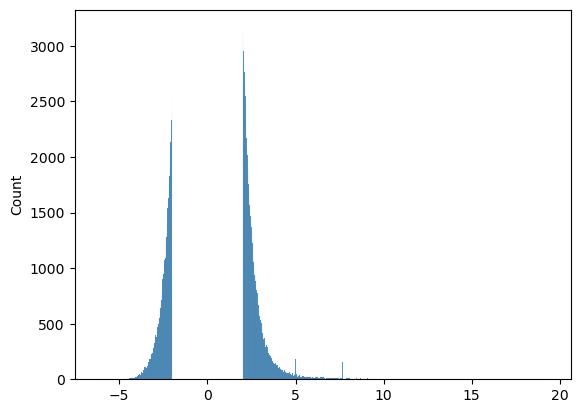

In [57]:
sns.histplot(scored[scored.abs()>=2].stack(), binwidth=0.01)

In [101]:
adtbi_df = scored[scored.abs()>=2].stack().reset_index()
adtbi_df.columns = ['Gene', 'Sample', 'Z-Score']
adtbi_df['Sample'] = adtbi_df['Sample'].astype(int).map(sample_names)
adtbi_df['Threshold'] = adtbi_df['Z-Score'].map(lambda x: 1 if x>0 else -1)
adtbi_df

,Gene,Sample,Z-Score,Threshold
0,A1BG,496100278_FWM_no dementia_TBI_90-94_M,2.470769,1
1,A1BG,496100362_FWM_no dementia_no TBI_78_M,2.340857,1
2,A1BG,496100402_FWM_no dementia_no TBI_90-94_F,2.198126,1
3,A1BG,496100409_FWM_no dementia_TBI_85_M,3.126956,1
4,A1BG,496100469_TCx_no dementia_TBI_89_M,-2.560994,-1
...,...,...,...,...
312853,ZZZ3,496100611_FWM_no dementia_no TBI_84_M,2.545059,1
312854,ZZZ3,496100616_FWM_no dementia_TBI_84_M,2.575547,1
312855,ZZZ3,496100620_FWM_possible Alzheimer's disease_no ...,2.319420,1
312856,ZZZ3,496100626_FWM_no dementia_TBI_86_M,2.511967,1


<Axes: ylabel='Frequency'>

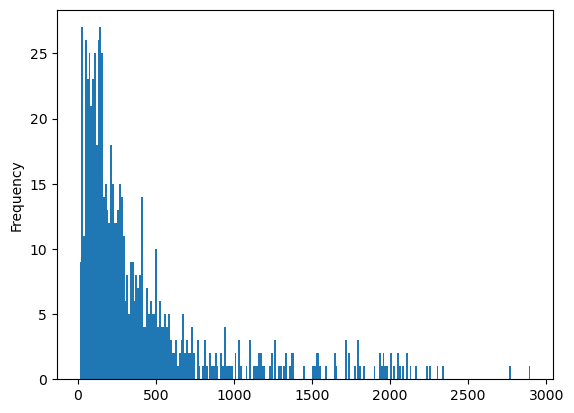

In [104]:
adtbi_df.groupby(['Sample', 'Threshold'])['Gene'].count().plot.hist(bins=250)

In [60]:
adtbi_df.nunique()

Gene        18548
Group         377
Z-score    308955
dtype: int64

## Prepare Data for SQL Ingestion

### Dataset

In [67]:
# id, name, name_without_resource, description, association, gene_set_description, gene_sets_description, attribute_set_description, positive_association, negative_association, is_signed, is_continuous_valued, last_updated, directory, num_page_views, resource_fk, measurement_fk, dataset_group_fk, attribute_type_fk, attribute_group_fk, evidence_type, evidence_group, measurement_bias, attribute_type_plural, is_archived
(193, 'Allen Brain Atlas Aging Dementia and Traumatic Brain Injury Gene Expression Profiles', 'Aging Dementia and Traumatic Brain Injury Gene Expression Profiles', 'mRNA expression profiles for dementia and traumatic brain injuries (TBI) from aging brain tissue', 'gene-tissue sample associations by differential expression of gene across tissue samples', 'genes with high or low expression in {0} relative to other tissue samples from the Allen Brain Atlas Aging Dementia and Traumatic Brain Injury Gene Expression Profiles dataset.', 'sets of genes with high or low expression in each tissue sample relative to other tissue samples from the Allen Brain Atlas Aging Dementia and Traumatic Brain Injury Gene Expression Profiles dataset.', 'tissue samples with high or low expression of {0} gene relative to other tissue samples from the Allen Brain Atlas Aging Dementia and Traumatic Brain Injury Gene Expression Profiles dataset.', 'high expression', 'low expression', 1, 1, '2025-10-20', 'brainatlasaging', 0, 2, 16, 7, 5, 1, 'gene expression by RNA-seq', 'primary experimental data', 'high throughput, data driven', 'tissue samples')

(193,
 'Allen Brain Atlas Aging Dementia and Traumatic Brain Injury Gene Expression Profiles',
 'Aging Dementia and Traumatic Brain Injury Gene Expression Profiles',
 'mRNA expression profiles for dementia and traumatic brain injuries (TBI) from aging brain tissue',
 'gene-tissue sample associations by differential expression of gene across tissue samples',
 'genes with high or low expression in {0} relative to other tissue samples from the Allen Brain Atlas Aging Dementia and Traumatic Brain Injury Gene Expression Profiles dataset.',
 'sets of genes with high or low expression in each tissue sample relative to other tissue samples from the Allen Brain Atlas Aging Dementia and Traumatic Brain Injury Gene Expression Profiles dataset.',
 'tissue samples with high or low expression of {0} gene relative to other tissue samples from the Allen Brain Atlas Aging Dementia and Traumatic Brain Injury Gene Expression Profiles dataset.',
 'high expression',
 'low expression',
 1,
 1,
 '2025-10-20'

### Publication

In [68]:
#(id, long_citation, short_citation, url, pmid, pubmed_url, first_author_last_name, first_author_initials, journal_abbreviation, year, title, volume, pages)
(175, 'Miller JA, et al. (2017) Neuropathological and transcriptomic characteristics of the aged brain. eLife. 6:e31126', 'Miller, eLife, 2017', 'dx.doi.org/10.7554/eLife.31126', 29120328, 'https://pubmed.ncbi.nlm.nih.gov/29120328', 'Miller', 'JA', 'eLife', 2017, 'TNeuropathological and transcriptomic characteristics of the aged brain', 6, 'e31126')

(282, 193, 175)

(282, 193, 175)

### Attribute

In [106]:
attributes = pd.read_csv('../../tables/attribute.txt', sep='\t')
attributes['name_from_naming_authority'] = attributes['name_from_naming_authority'].str.lower().str.strip()
attributes = attributes.set_index('name_from_naming_authority')
attributefks = attributes['id'].to_dict()
index = 562575

for sample in adtbi_df['Sample'].unique():
    if sample.lower() not in attributes.index:
        sample_id = int(sample.split('_')[0])
        print((index, sample, sample_id, sample_descs[sample_id], 28), end=',\n')
        attributefks[sample.lower()] = index
        index += 1

(562575, '496100278_FWM_no dementia_TBI_90-94_M', 496100278, 'White matter of forebrain tissue sample from donor with no dementia, TBI, 90-94 years, male', 28),
(562576, '496100362_FWM_no dementia_no TBI_78_M', 496100362, 'White matter of forebrain tissue sample from donor with no dementia, no TBI, 78 years, male', 28),
(562577, '496100402_FWM_no dementia_no TBI_90-94_F', 496100402, 'White matter of forebrain tissue sample from donor with no dementia, no TBI, 90-94 years, female', 28),
(562578, '496100409_FWM_no dementia_TBI_85_M', 496100409, 'White matter of forebrain tissue sample from donor with no dementia, TBI, 85 years, male', 28),
(562579, '496100469_TCx_no dementia_TBI_89_M', 496100469, 'Temporal neocortex tissue sample from donor with no dementia, TBI, 89 years, male', 28),
(562580, "496100470_HIP_possible Alzheimer's disease_TBI_89_F", 496100470, "Hippocampus (hippocampal formation) tissue sample from donor with possible Alzheimer's disease, TBI, 89 years, female", 28),
(5625

### Gene Set

In [107]:
index = 139400000
genesetfks = {}

for sample in adtbi_df['Sample'].unique():
    sample_id = int(sample.split('_')[0])
    print((index, sample, sample_id, sample_descs[sample_id], 193, 5, attributefks[sample.lower()]), end=',\n')
    genesetfks[sample] = index
    index += 1

(139400000, '496100278_FWM_no dementia_TBI_90-94_M', 496100278, 'White matter of forebrain tissue sample from donor with no dementia, TBI, 90-94 years, male', 193, 5, 562575),
(139400001, '496100362_FWM_no dementia_no TBI_78_M', 496100362, 'White matter of forebrain tissue sample from donor with no dementia, no TBI, 78 years, male', 193, 5, 562576),
(139400002, '496100402_FWM_no dementia_no TBI_90-94_F', 496100402, 'White matter of forebrain tissue sample from donor with no dementia, no TBI, 90-94 years, female', 193, 5, 562577),
(139400003, '496100409_FWM_no dementia_TBI_85_M', 496100409, 'White matter of forebrain tissue sample from donor with no dementia, TBI, 85 years, male', 193, 5, 562578),
(139400004, '496100469_TCx_no dementia_TBI_89_M', 496100469, 'Temporal neocortex tissue sample from donor with no dementia, TBI, 89 years, male', 193, 5, 562579),
(139400005, "496100470_HIP_possible Alzheimer's disease_TBI_89_F", 496100470, "Hippocampus (hippocampal formation) tissue sample fr

### Associations

In [110]:
index = 98000000

genes = pd.read_csv('../../tables/gene.txt', sep='\t')
genes['symbol'] = genes['symbol'].str.upper()
genes = genes.set_index('symbol')
genefks = genes['id'].to_dict()

associations = adtbi_df.copy()
associations['Gene'] = associations['Gene'].apply(lambda x: genefks[x])
associations['Sample'] = associations['Sample'].apply(lambda x: genesetfks[x])
associations = associations.get(['Gene', 'Sample', 'Z-Score', 'Threshold'])
associations.columns = ['gene_fk', 'gene_set_fk', 'standardized_value', 'threshold_value']
associations = associations.drop_duplicates().reset_index(drop=True)
associations.index += index
associations = associations.rename_axis('id')
associations.to_csv('../../harmonizome-update/brainatlasaging.csv')
associations

,gene_fk,gene_set_fk,standardized_value,threshold_value
id,,,,
98000000,31281,139400000,2.470769,1
98000001,31281,139400001,2.340857,1
98000002,31281,139400002,2.198126,1
98000003,31281,139400003,3.126956,1
98000004,31281,139400004,-2.560994,-1
...,...,...,...,...
98312853,44608,139400160,2.545059,1
98312854,44608,139400011,2.575547,1
98312855,44608,139400012,2.319420,1


## Create Downloads

In [2]:
output_path = 'downloads'

### Binary Matrix

In [112]:
binarymatrix = pd.crosstab(adtbi_df['Gene'], adtbi_df['Sample'], values=adtbi_df['Threshold'], aggfunc=np.mean).replace(np.nan, 0)
binarymatrixT = binarymatrix.T
binarymatrix.to_csv(f'{output_path}/gene_attribute_matrix.txt.gz', sep='\t', compression='gzip')
binarymatrix

Sample,488395315_TCx_no dementia_no TBI_90-94_F,496100277_FWM_no dementia_no TBI_90-94_M,496100278_FWM_no dementia_TBI_90-94_M,496100279_TCx_no dementia_TBI_90-94_M,496100281_HIP_probable Alzheimer's disease_no TBI_90-94_M,496100283_PCx_probable Alzheimer's disease_no TBI_90-94_M,496100284_FWM_probable Alzheimer's disease_no TBI_90-94_M,496100285_TCx_probable Alzheimer's disease_no TBI_90-94_M,496100287_TCx_no dementia_TBI_90-94_M,496100288_HIP_no dementia_TBI_90-94_M,...,496100661_PCx_no dementia_TBI_90-94_F,496100663_TCx_no dementia_no TBI_86_M,496100664_HIP_probable Alzheimer's disease_no TBI_82_F,496100665_PCx_probable Alzheimer's disease_TBI_90-94_F,496100666_HIP_probable Alzheimer's disease_TBI_83_F,496100667_TCx_no dementia_TBI_90-94_F,496100669_FWM_no dementia_TBI_90-94_F,496100670_TCx_probable Alzheimer's disease_TBI_90-94_F,496100671_HIP_no dementia_TBI_90-94_F,496100672_FWM_no dementia_no TBI_90-94_F
Gene,,,,,,,,,,,,,,,,,,,,,
A1BG,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A1CF,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A2M,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A2ML1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A3GALT2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11A,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ZYG11B,0.0,-1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ZYX,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Gene Attribute Edge List

In [115]:
edgelist = adtbi_df.copy()
edgelist['Gene ID'] = edgelist['Gene'].map(geneids).astype(int)
edgelist['Sample ID'] = edgelist['Sample'].map(lambda x: x.split('_')[0]).astype(int)
edgelist = edgelist[['Gene', 'Gene ID', 'Sample', 'Sample ID', 'Z-Score', 'Threshold']].reset_index(drop=True)
edgelist.to_csv(f'{output_path}/gene_attribute_edges.txt.gz', sep='\t', compression='gzip')
edgelist

,Gene,Gene ID,Sample,Sample ID,Z-Score,Threshold
0,A1BG,1,496100278_FWM_no dementia_TBI_90-94_M,496100278,2.470769,1
1,A1BG,1,496100362_FWM_no dementia_no TBI_78_M,496100362,2.340857,1
2,A1BG,1,496100402_FWM_no dementia_no TBI_90-94_F,496100402,2.198126,1
3,A1BG,1,496100409_FWM_no dementia_TBI_85_M,496100409,3.126956,1
4,A1BG,1,496100469_TCx_no dementia_TBI_89_M,496100469,-2.560994,-1
...,...,...,...,...,...,...
312853,ZZZ3,26009,496100611_FWM_no dementia_no TBI_84_M,496100611,2.545059,1
312854,ZZZ3,26009,496100616_FWM_no dementia_TBI_84_M,496100616,2.575547,1
312855,ZZZ3,26009,496100620_FWM_possible Alzheimer's disease_no ...,496100620,2.319420,1
312856,ZZZ3,26009,496100626_FWM_no dementia_TBI_86_M,496100626,2.511967,1


### Gene List

In [116]:
geneslist = edgelist[['Gene', 'Gene ID']].drop_duplicates().reset_index(drop=True)
geneslist.to_csv(f'{output_path}/gene_list_terms.txt.gz', sep='\t', compression='gzip')
geneslist

,Gene,Gene ID
0,A1BG,1
1,A1CF,29974
2,A2M,2
3,A2ML1,144568
4,A3GALT2,127550
...,...,...
18543,ZYG11A,440590
18544,ZYG11B,79699
18545,ZYX,7791
18546,ZZEF1,23140


### Attribute List

In [118]:
attributeslist = edgelist[['Sample', 'Sample ID']].drop_duplicates().reset_index(drop=True)
attributeslist.to_csv(f'{output_path}/attribute_list_entries.txt.gz', sep='\t', compression='gzip')
attributeslist

,Sample,Sample ID
0,496100278_FWM_no dementia_TBI_90-94_M,496100278
1,496100362_FWM_no dementia_no TBI_78_M,496100362
2,496100402_FWM_no dementia_no TBI_90-94_F,496100402
3,496100409_FWM_no dementia_TBI_85_M,496100409
4,496100469_TCx_no dementia_TBI_89_M,496100469
...,...,...
372,496100617_TCx_no dementia_TBI_95-99_F,496100617
373,496100513_TCx_no dementia_TBI_95-99_M,496100513
374,496100540_TCx_probable Alzheimer's disease_TBI...,496100540
375,496100341_TCx_no dementia_no TBI_81_M,496100341


### Up Gene Set Library

In [120]:
with open(f'{output_path}/gene_set_library_up_crisp.gmt', 'w') as f:
    arr = binarymatrix.reset_index(drop=True).to_numpy(dtype=np.int_)
    attributes = binarymatrix.columns

    w, h = arr.shape
    for i in tqdm(range(h)):
        if len([*binarymatrix.index[arr[:, i] == 1]])>= 5:
            print(attributes[i], '', *binarymatrix.index[arr[:, i] == 1], sep='\t', end='\n', file=f)

100%|██████████| 377/377 [00:00<00:00, 4566.89it/s]


### Down Gene Set Library

In [121]:
with open(f'{output_path}/gene_set_library_dn_crisp.gmt', 'w') as f:
    arr = binarymatrix.reset_index(drop=True).to_numpy(dtype=np.int_)
    attributes = binarymatrix.columns

    w, h = arr.shape
    for i in tqdm(range(h)):
        if len([*binarymatrix.index[arr[:, i] == -1]])>= 5:
            print(attributes[i], '', *binarymatrix.index[arr[:, i] == -1], sep='\t', end='\n', file=f)

100%|██████████| 377/377 [00:00<00:00, 6645.76it/s]


### Up Attribute Set Library

In [122]:
with open(f'{output_path}/attribute_set_library_up_crisp.gmt', 'w') as f:
    arr = binarymatrixT.reset_index(drop=True).to_numpy(dtype=np.int_)
    genes = binarymatrixT.columns

    w, h = arr.shape
    for i in tqdm(range(h)):
        if len([*binarymatrixT.index[arr[:, i] == 1]])>= 5:
            print(genes[i], '', *binarymatrixT.index[arr[:, i] == 1], sep='\t', end='\n', file=f)

100%|██████████| 18548/18548 [00:00<00:00, 54669.19it/s]


### Down Attribute Set Library

In [123]:
with open(f'{output_path}/attribute_set_library_dn_crisp.gmt', 'w') as f:
    arr = binarymatrixT.reset_index(drop=True).to_numpy(dtype=np.int_)
    genes = binarymatrixT.columns

    w, h = arr.shape
    for i in tqdm(range(h)):
        if len([*binarymatrixT.index[arr[:, i] == -1]])>= 5:
            print(genes[i], '', *binarymatrixT.index[arr[:, i] == -1], sep='\t', end='\n', file=f)

100%|██████████| 18548/18548 [00:00<00:00, 70044.23it/s]


### Gene Similarity Matrix

In [160]:
gene_similarity_matrix = dist.pdist(binarymatrix.to_numpy(dtype=np.int_), 'cosine')
gene_similarity_matrix = dist.squareform(gene_similarity_matrix)
gene_similarity_matrix = 1 - gene_similarity_matrix

gene_similarity_matrix = pd.DataFrame(data=gene_similarity_matrix, index=binarymatrix.index, columns=binarymatrix.index)
gene_similarity_matrix.index.name = None
gene_similarity_matrix.columns.name = None
gene_similarity_matrix.to_csv(f'{output_path}/gene_similarity_matrix_cosine.txt.gz', sep='\t', compression='gzip')
gene_similarity_matrix

,A1BG,A1CF,A2M,A2ML1,A3GALT2,A4GALT,A4GNT,AAAS,AACS,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
A1BG,1.000000,0.121716,0.059235,0.000000,0.110096,0.000000,0.000000,0.394405,-0.338062,0.064550,...,0.000000,0.077850,0.438357,-0.155700,0.143223,0.000000,-0.125245,0.000000,0.056344,0.298142
A1CF,0.121716,1.000000,0.000000,-0.054074,0.000000,0.000000,0.114332,0.051434,0.000000,0.176777,...,0.096225,0.071067,0.057166,-0.071067,0.065372,0.051434,-0.057166,-0.068041,-0.051434,0.045361
A2M,0.059235,0.000000,1.000000,0.052632,0.048912,0.229416,0.166924,0.000000,-0.100125,0.172062,...,-0.093659,-0.069171,0.055641,-0.276686,0.063628,-0.050063,-0.222566,0.000000,0.050063,0.044151
A2ML1,0.000000,-0.054074,0.052632,1.000000,0.000000,0.286770,0.000000,-0.050063,0.000000,0.000000,...,0.000000,-0.069171,0.000000,0.000000,0.000000,0.100125,-0.055641,-0.066227,0.000000,0.000000
A3GALT2,0.110096,0.000000,0.048912,0.000000,1.000000,0.053300,0.051709,0.139573,-0.139573,0.106600,...,0.000000,0.064282,0.155126,0.000000,0.177394,0.046524,-0.155126,0.000000,0.093048,0.123091
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11A,0.000000,0.051434,-0.050063,0.100125,0.046524,-0.109109,0.000000,0.095238,-0.095238,-0.054554,...,0.000000,0.000000,0.052926,0.000000,0.121046,1.000000,-0.052926,-0.062994,0.095238,0.125988
ZYG11B,-0.125245,-0.057166,-0.222566,-0.055641,-0.155126,-0.363803,-0.058824,0.000000,0.317554,-0.060634,...,0.396059,0.073127,-0.117647,0.292509,-0.201802,-0.052926,1.000000,-0.140028,-0.317554,-0.233380
ZYX,0.000000,-0.068041,0.000000,-0.066227,0.000000,0.144338,0.000000,-0.125988,0.000000,0.000000,...,0.000000,-0.261116,0.000000,0.000000,0.000000,-0.062994,-0.140028,1.000000,0.125988,-0.055556
ZZEF1,0.056344,-0.051434,0.050063,0.000000,0.093048,0.109109,0.000000,0.095238,-0.142857,0.054554,...,-0.178174,-0.065795,0.158777,-0.131590,0.060523,0.095238,-0.317554,0.125988,1.000000,0.293972


### Attribute Similarity Matrix

In [124]:
attribute_similarity_matrix = dist.pdist(binarymatrixT.to_numpy(dtype=np.int_), 'cosine')
attribute_similarity_matrix = dist.squareform(attribute_similarity_matrix)
attribute_similarity_matrix = 1 - attribute_similarity_matrix

attribute_similarity_matrix = pd.DataFrame(data=attribute_similarity_matrix, index=binarymatrixT.index, columns=binarymatrixT.index)
attribute_similarity_matrix.index.name = None
attribute_similarity_matrix.columns.name = None
attribute_similarity_matrix.to_csv(f'{output_path}/attribute_similarity_matrix_cosine.txt.gz', sep='\t', compression='gzip')
attribute_similarity_matrix

,488395315_TCx_no dementia_no TBI_90-94_F,496100277_FWM_no dementia_no TBI_90-94_M,496100278_FWM_no dementia_TBI_90-94_M,496100279_TCx_no dementia_TBI_90-94_M,496100281_HIP_probable Alzheimer's disease_no TBI_90-94_M,496100283_PCx_probable Alzheimer's disease_no TBI_90-94_M,496100284_FWM_probable Alzheimer's disease_no TBI_90-94_M,496100285_TCx_probable Alzheimer's disease_no TBI_90-94_M,496100287_TCx_no dementia_TBI_90-94_M,496100288_HIP_no dementia_TBI_90-94_M,...,496100661_PCx_no dementia_TBI_90-94_F,496100663_TCx_no dementia_no TBI_86_M,496100664_HIP_probable Alzheimer's disease_no TBI_82_F,496100665_PCx_probable Alzheimer's disease_TBI_90-94_F,496100666_HIP_probable Alzheimer's disease_TBI_83_F,496100667_TCx_no dementia_TBI_90-94_F,496100669_FWM_no dementia_TBI_90-94_F,496100670_TCx_probable Alzheimer's disease_TBI_90-94_F,496100671_HIP_no dementia_TBI_90-94_F,496100672_FWM_no dementia_no TBI_90-94_F
488395315_TCx_no dementia_no TBI_90-94_F,1.000000,0.003949,-0.006776,0.008853,0.004654,0.007658,0.022653,0.024022,0.036263,0.004720,...,0.000000,0.007910,0.013997,0.017908,0.033577,0.006920,0.017869,0.011080,-0.004574,0.019904
496100277_FWM_no dementia_no TBI_90-94_M,0.003949,1.000000,0.561480,-0.008111,-0.010233,-0.015435,0.003321,-0.002515,0.000000,0.004324,...,-0.011509,0.001933,0.010259,0.003938,0.021680,-0.010144,0.008185,-0.006767,0.005029,0.005835
496100278_FWM_no dementia_TBI_90-94_M,-0.006776,0.561480,1.000000,0.015463,0.000000,-0.008026,-0.003165,-0.007193,-0.004223,0.022259,...,-0.010971,-0.010132,0.004890,-0.002502,0.045244,-0.014506,-0.004682,-0.009032,-0.002397,0.018079
496100279_TCx_no dementia_TBI_90-94_M,0.008853,-0.008111,0.015463,1.000000,0.019117,0.015728,0.000000,0.021145,0.037239,0.009693,...,0.007167,0.016246,0.007187,0.007356,0.006568,0.028427,0.018349,0.007585,0.014092,0.032703
496100281_HIP_probable Alzheimer's disease_no TBI_90-94_M,0.004654,-0.010233,0.000000,0.019117,1.000000,0.020671,0.039134,0.025938,0.009789,0.081537,...,0.007535,0.005694,0.034005,0.000000,0.075962,0.011208,0.004823,0.000000,0.066677,0.004298
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
496100667_TCx_no dementia_TBI_90-94_F,0.006920,-0.010144,-0.014506,0.028427,0.011208,0.043033,0.043644,0.033059,0.009704,0.000000,...,0.151266,0.080433,0.016855,0.023002,-0.005134,1.000000,0.114755,0.005930,0.040393,0.012783
496100669_FWM_no dementia_TBI_90-94_F,0.017869,0.008185,-0.004682,0.018349,0.004823,0.031746,0.056344,0.021339,0.018791,0.019566,...,0.130189,0.043722,0.014506,0.007424,0.000000,0.114755,1.000000,0.007655,0.037925,0.041256
496100670_TCx_probable Alzheimer's disease_TBI_90-94_F,0.011080,-0.006767,-0.009032,0.007585,0.000000,0.026247,0.007764,0.052928,0.020715,0.004044,...,0.000000,0.022592,0.011993,0.122757,-0.005480,0.005930,0.007655,1.000000,0.003919,0.006822
496100671_HIP_no dementia_TBI_90-94_F,-0.004574,0.005029,-0.002397,0.014092,0.066677,0.016254,0.004808,0.014568,-0.006414,0.090157,...,0.044437,0.013991,0.029709,0.007602,0.018665,0.040393,0.037925,0.003919,1.000000,0.004225


### Standardized Matrix

In [125]:
standardizedmatrix = scored.rename(lambda x: sample_names[int(x)], axis=1)
standardizedmatrix.to_csv(f'{output_path}/gene_attribute_matrix_standardized.txt.gz', sep='\t', compression='gzip')
standardizedmatrix

,488395315_TCx_no dementia_no TBI_90-94_F,496100277_FWM_no dementia_no TBI_90-94_M,496100278_FWM_no dementia_TBI_90-94_M,496100279_TCx_no dementia_TBI_90-94_M,496100281_HIP_probable Alzheimer's disease_no TBI_90-94_M,496100283_PCx_probable Alzheimer's disease_no TBI_90-94_M,496100284_FWM_probable Alzheimer's disease_no TBI_90-94_M,496100285_TCx_probable Alzheimer's disease_no TBI_90-94_M,496100287_TCx_no dementia_TBI_90-94_M,496100288_HIP_no dementia_TBI_90-94_M,...,496100661_PCx_no dementia_TBI_90-94_F,496100663_TCx_no dementia_no TBI_86_M,496100664_HIP_probable Alzheimer's disease_no TBI_82_F,496100665_PCx_probable Alzheimer's disease_TBI_90-94_F,496100666_HIP_probable Alzheimer's disease_TBI_83_F,496100667_TCx_no dementia_TBI_90-94_F,496100669_FWM_no dementia_TBI_90-94_F,496100670_TCx_probable Alzheimer's disease_TBI_90-94_F,496100671_HIP_no dementia_TBI_90-94_F,496100672_FWM_no dementia_no TBI_90-94_F
gene_id \ rnaseq_profile_id,,,,,,,,,,,,,,,,,,,,,
A1BG,-0.613867,0.853537,2.470769,-0.194722,-0.425913,0.005387,-0.071420,-0.935095,-0.751316,-0.333157,...,-0.667434,-0.515422,-0.077491,-1.032960,-1.337449,-0.074485,0.681259,-0.993763,-0.183520,-0.185590
A1CF,-1.154269,-0.665218,-0.685907,0.414513,-0.299981,-0.395589,-0.093434,0.581489,-0.441207,0.412301,...,1.069146,2.977440,-0.103209,-0.057950,-0.885257,1.838112,-0.060123,-1.085413,0.020444,-0.836615
A2M,-0.210978,0.203266,0.067348,-0.580898,0.465117,-0.692203,-0.470470,-0.918118,-0.667207,0.235050,...,-1.015937,-0.492556,-0.244539,0.218939,0.777722,-1.021241,-0.677006,-0.980300,0.237349,0.954884
A2ML1,-1.426863,0.362462,-0.656368,-1.506222,0.198298,-0.401149,-0.610664,-0.417489,-0.662684,-0.244122,...,-1.016029,-1.462632,0.695202,1.442248,0.923557,-0.622963,-0.039978,0.245623,0.787802,0.062796
A3GALT2,3.357156,3.836776,-0.384212,-0.463197,-0.467994,-0.469038,-0.467765,1.351721,1.362548,-0.462442,...,-0.468833,-0.467873,-0.465297,-0.466388,-0.469935,-0.469223,-0.469686,-0.465597,-0.469407,-0.470089
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZYG11A,0.795863,2.491096,1.924621,-0.527592,0.614452,0.508891,-0.134587,-0.739269,0.044468,0.335697,...,-0.417343,0.007369,-0.752781,0.988307,-0.568926,-0.978128,-0.981940,-0.043676,-0.702272,-0.345341
ZYG11B,0.037983,-2.089599,-1.668417,1.132585,0.090625,0.477481,0.677955,1.375303,0.650663,-0.257476,...,0.781887,1.182523,0.384247,0.057392,-0.556564,0.896960,0.406605,0.742124,-0.099866,0.203454
ZYX,0.110657,-1.582519,-1.173335,0.220316,-0.634490,1.031807,0.826267,0.375812,1.259008,-0.456639,...,0.461359,0.004572,-1.127968,1.387977,-0.700901,0.337456,0.402984,1.342963,-1.199497,0.721806


### Knowledge Graph Serialization

In [156]:
nodes = {}
edges = []

for gene in geneslist.index:
    gene = geneslist.loc[gene]
    nodes[int(gene['Gene ID'])] = {
        "type":"gene",
        "properties": {
            "id":int(gene['Gene ID']),
            "label":gene['Gene']
        }}

for attr in attributeslist.index:
    attr = attributeslist.loc[attr]
    nodes[f"ABAAgingBrainMap_{attr['Sample ID']}"] = {
        "type":"tissue sample",
        "properties": {
            "label":attr['Sample'],
            "id":f"ABAAgingBrainMap_{attr['Sample ID']}"
        }}

for edge in edgelist.index:
    edge = edgelist.loc[edge]
    edges.append({
        "source": int(edge['Gene ID']),
        "relation": "over-expressed in" if edge['Threshold'] == 1 else 'under-expressed in',
        "target": f"ABAAgingBrainMap_{attr['Sample ID']}",
        "properties":{
            "id": str(edge['Gene ID'])+":"+f"ABAAgingBrainMap_{attr['Sample ID']}",
            "source_label":edge['Gene'],
            "source_id": int(edge['Gene ID']),
            "target_id": f"ABAAgingBrainMap_{attr['Sample ID']}",
            "target_label":edge['Sample'],
            "directed":True,
            "standardized":edge['Z-Score'],
            "threshold": int(edge['Threshold']),
        }})

#### RDF

In [153]:
with open(output_path+'/kg_serializations/allenbrainaging.rdf', 'w') as f:
    print('@prefix gene: <https://ncbi.nlm.nih.gov/gene/> .', file=f)
    print('@prefix RO: <http://purl.obolibrary.org/RO_> .', file=f)
    
    print('', file=f)
    for edge in edges:
        print(f"gene:{edge['properties']['source_id']}", f"{'RO:0002245' if edge['properties']['threshold']==1 else 'RO:0002246'}", f"<{edge['properties']['target_id']}>", end=' .\n', file=f)

#### JSON

In [157]:
with open(output_path+'/kg_serializations/allenbrainaging.json', 'w') as f:
    serial = json.dump(
        {
            "Version":"1", 
            "nodes": nodes,
            "edges": edges
        }, indent=4, fp=f)

#### TSV

In [158]:
nodeframe = pd.DataFrame(nodes).T
nodeframe['id'] = nodeframe['properties'].apply(lambda x: x['id'])
nodeframe['label'] = nodeframe['properties'].apply(lambda x: x['label'])
namespace = {'gene':'NCBI Entrez', 'tissue sample':'Allen Brain Atlas Aging Brain Map'}
nodeframe['namespace'] = nodeframe['type'].map(namespace)
nodeframe = nodeframe.get(['namespace', 'id', 'label']).reset_index(drop=True)
nodeframe.to_csv(output_path+'/kg_serializations/allenbrainaging_tsv/nodes.tsv', sep='\t')
nodeframe

,namespace,id,label
0,NCBI Entrez,1,A1BG
1,NCBI Entrez,29974,A1CF
2,NCBI Entrez,2,A2M
3,NCBI Entrez,144568,A2ML1
4,NCBI Entrez,127550,A3GALT2
...,...,...,...
18920,Allen Brain Atlas Aging Brain Map,ABAAgingBrainMap_496100617,496100617_TCx_no dementia_TBI_95-99_F
18921,Allen Brain Atlas Aging Brain Map,ABAAgingBrainMap_496100513,496100513_TCx_no dementia_TBI_95-99_M
18922,Allen Brain Atlas Aging Brain Map,ABAAgingBrainMap_496100540,496100540_TCx_probable Alzheimer's disease_TBI...
18923,Allen Brain Atlas Aging Brain Map,ABAAgingBrainMap_496100341,496100341_TCx_no dementia_no TBI_81_M


In [159]:
edgeframe = pd.DataFrame(edges)
edgeframe['standardized'] = edgeframe['properties'].apply(lambda x: x['standardized'])
edgeframe['threshold'] = edgeframe['properties'].apply(lambda x: x['threshold'])
edgeframe = edgeframe.get(['source', 'relation', 'target','standardized', 'threshold'])
edgeframe.to_csv(output_path+'/kg_serializations/allenbrainaging_tsv/edges.tsv', sep='\t')
edgeframe

,source,relation,target,standardized,threshold
0,1,over-expressed in,ABAAgingBrainMap_496100669,2.470769,1
1,1,over-expressed in,ABAAgingBrainMap_496100669,2.340857,1
2,1,over-expressed in,ABAAgingBrainMap_496100669,2.198126,1
3,1,over-expressed in,ABAAgingBrainMap_496100669,3.126956,1
4,1,under-expressed in,ABAAgingBrainMap_496100669,-2.560994,-1
...,...,...,...,...,...
312853,26009,over-expressed in,ABAAgingBrainMap_496100669,2.545059,1
312854,26009,over-expressed in,ABAAgingBrainMap_496100669,2.575547,1
312855,26009,over-expressed in,ABAAgingBrainMap_496100669,2.319420,1
312856,26009,over-expressed in,ABAAgingBrainMap_496100669,2.511967,1


## Prepare Visualizations

### Gene-Attribute Clustermap

In [10]:
binarymatrix = pd.read_csv(f'{output_path}/gene_attribute_matrix.txt.gz', sep='\t', compression='gzip', index_col=0)

/Users/ido/opt/anaconda3/envs/processing/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/Users/ido/opt/anaconda3/envs/processing/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


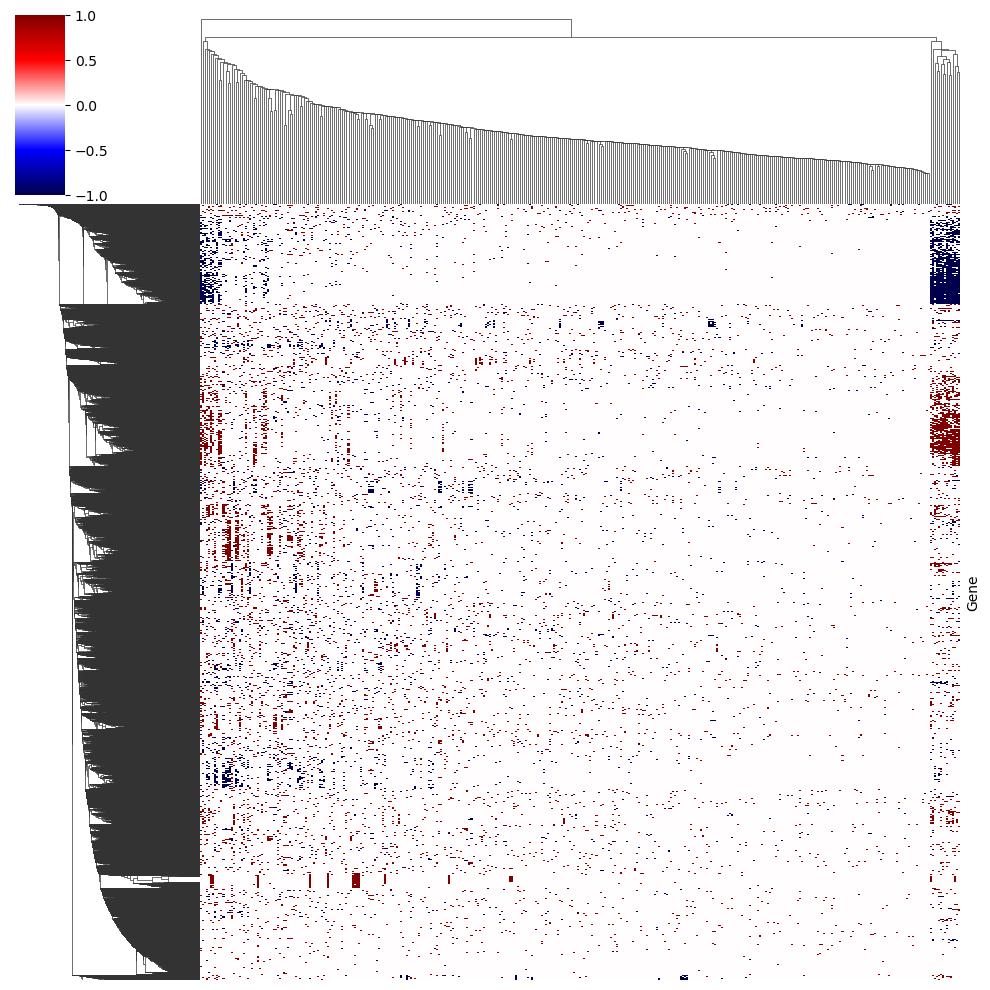

In [11]:
ax = sns.clustermap(binarymatrix, cmap='seismic', center=0, figsize=(10,10), xticklabels=False, yticklabels=False)

In [22]:
reord = binarymatrix.iloc[ax.dendrogram_row.reordered_ind,ax.dendrogram_col.reordered_ind]

<Axes: xlabel='Gene'>

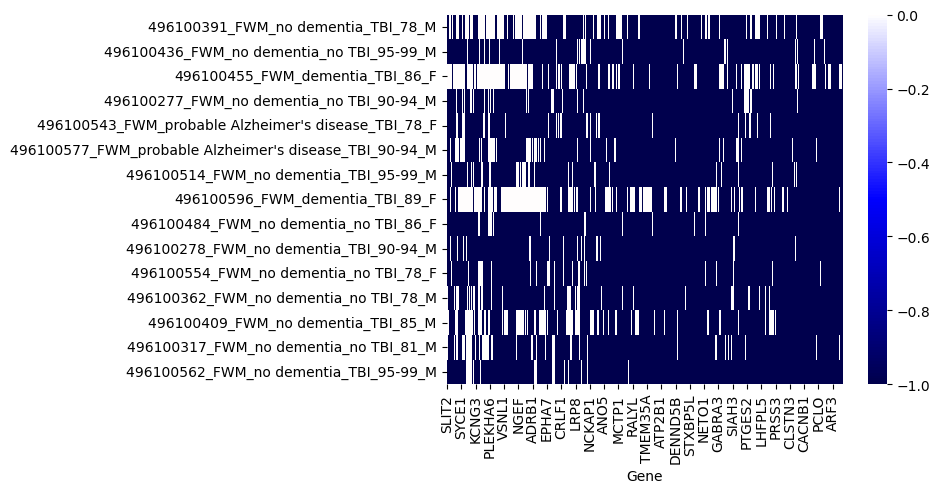

In [36]:
sns.heatmap(reord.iloc[1500:2000,-15:].T, cmap='seismic', center=0)

In [44]:
reord.iloc[:,:82].abs().sum().index

Index(['496100616_FWM_no dementia_TBI_84_M',
       '496100651_FWM_probable Alzheimer's disease_TBI_83_F',
       '496100608_FWM_no dementia_no TBI_78_M',
       '496100611_FWM_no dementia_no TBI_84_M',
       '496100474_FWM_possible Alzheimer's disease_TBI_89_F',
       '496100416_FWM_dementia_TBI_90-94_F',
       '496100367_FWM_no dementia_TBI_78_M',
       '496100494_HIP_no dementia_TBI_100+_F',
       '496100527_FWM_possible Alzheimer's disease_no TBI_90-94_M',
       '496100346_FWM_no dementia_TBI_81_M',
       '496100380_FWM_no dementia_no TBI_78_M',
       '496100307_FWM_possible Alzheimer's disease_no TBI_90-94_M',
       '496100407_FWM_probable Alzheimer's disease_no TBI_88_M',
       '496100390_PCx_probable Alzheimer's disease_no TBI_88_M',
       '496100405_TCx_probable Alzheimer's disease_no TBI_88_M',
       '496100316_TCx_no dementia_TBI_79_M',
       '496100622_HIP_no dementia_no TBI_78_M',
       '496100322_FWM_possible Alzheimer's disease_no TBI_100+_M',
       '496100

In [41]:
reord.iloc[:,-15:].abs().sum()

496100391_FWM_no dementia_TBI_78_M                        3846.0
496100436_FWM_no dementia_no TBI_95-99_M                  4394.0
496100455_FWM_dementia_TBI_86_F                           2932.0
496100277_FWM_no dementia_no TBI_90-94_M                  3455.0
496100543_FWM_probable Alzheimer's disease_TBI_78_F       4065.0
496100577_FWM_probable Alzheimer's disease_TBI_90-94_M    3985.0
496100514_FWM_no dementia_TBI_95-99_M                     3785.0
496100596_FWM_dementia_TBI_89_F                           3098.0
496100484_FWM_no dementia_no TBI_86_F                     4293.0
496100278_FWM_no dementia_TBI_90-94_M                     3802.0
496100554_FWM_no dementia_no TBI_78_F                     3774.0
496100362_FWM_no dementia_no TBI_78_M                     5002.0
496100409_FWM_no dementia_TBI_85_M                        4037.0
496100317_FWM_no dementia_no TBI_81_M                     4031.0
496100562_FWM_no dementia_TBI_95-99_M                     3985.0
dtype: float64

### Gene-Gene Similarity Clustermap

/Users/ido/opt/anaconda3/envs/processing/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/Users/ido/opt/anaconda3/envs/processing/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


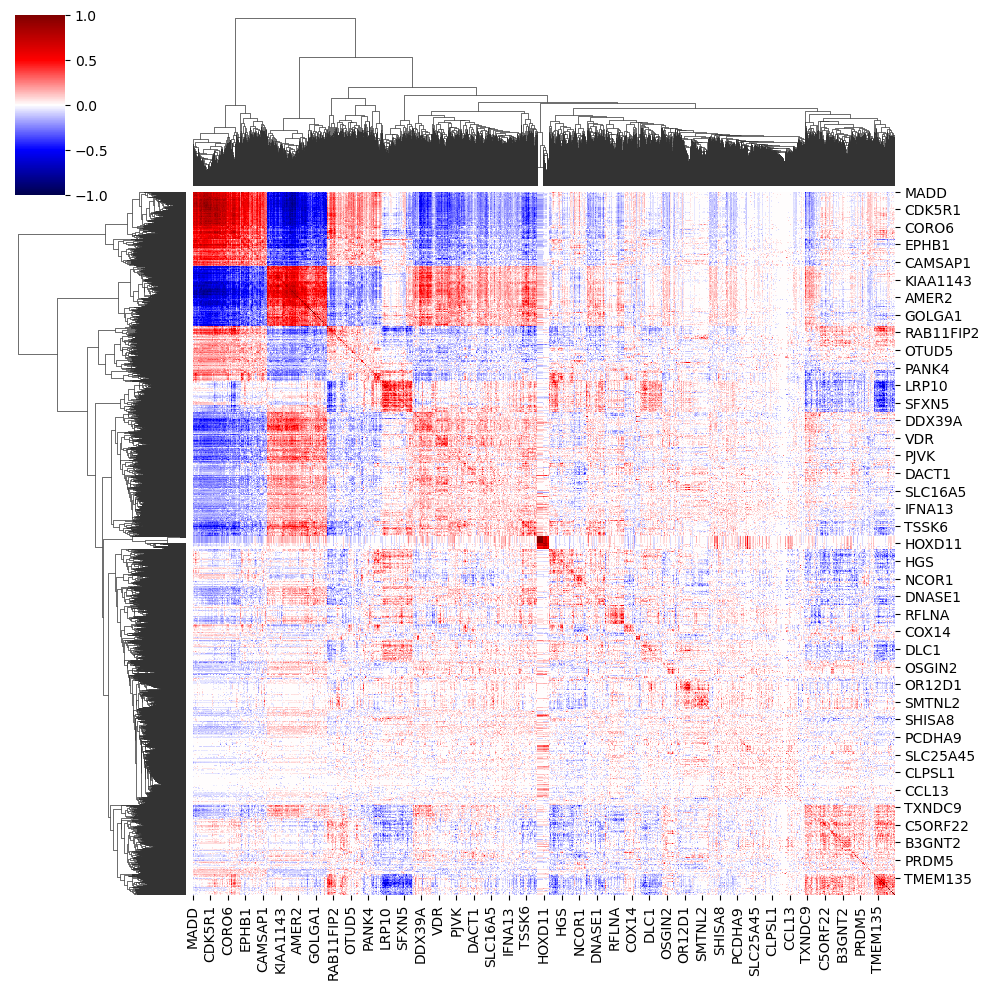

In [4]:
ax = sns.clustermap(gene_similarity_matrix, cmap='seismic', center=0)

### Attribute-Attribute Similarity Clustermap

/Users/ido/opt/anaconda3/envs/processing/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/Users/ido/opt/anaconda3/envs/processing/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


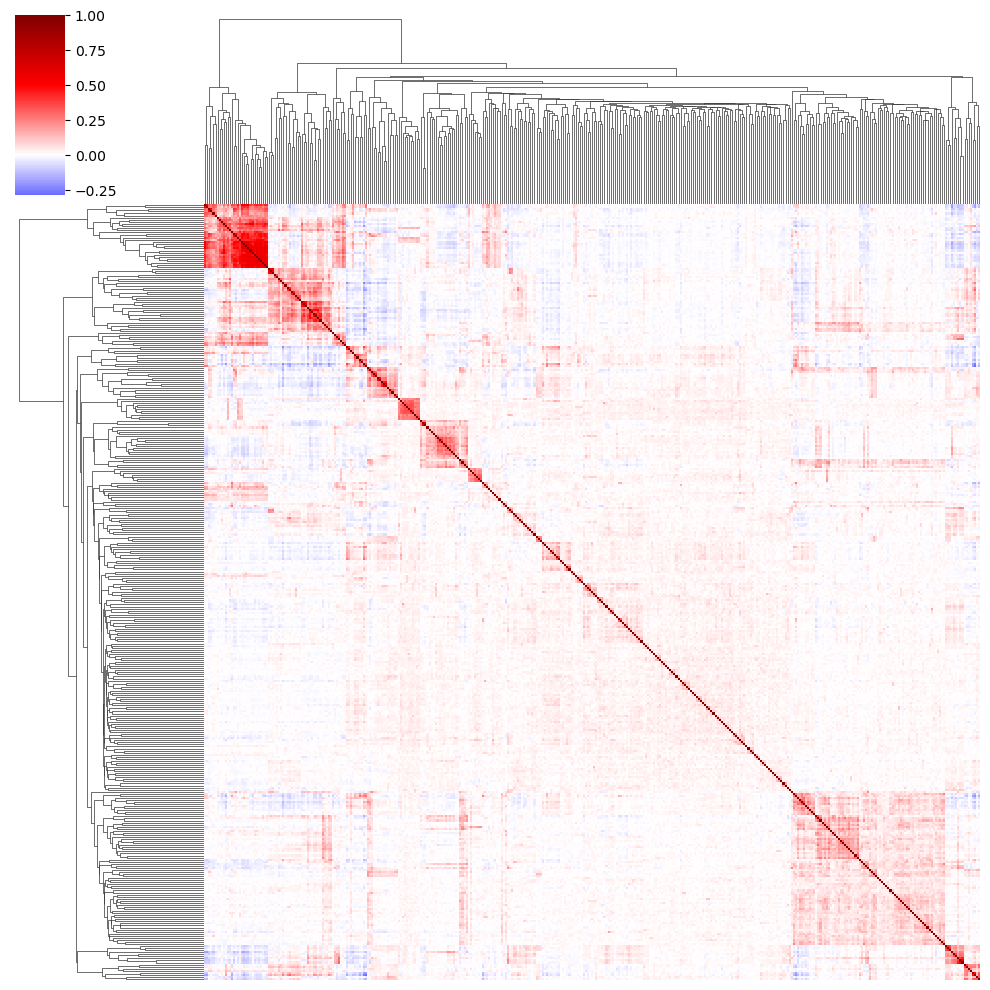

In [127]:
sns.clustermap(attribute_similarity_matrix, cmap='seismic', center=0, xticklabels=False, yticklabels=False)

### UMAP

In [5]:
def load_gmt(file, dir):
    gmt = OrderedDict()
    for line in file:
        term, blank, *geneset = line.strip().split('\t')
        gmt[term+'_'+dir] = ' '.join(set(geneset))
    return gmt
libdict = load_gmt(open(f'{output_path}/gene_set_library_up_crisp.gmt', 'r'), 'up')
libdict = libdict | load_gmt(open(f'{output_path}/gene_set_library_dn_crisp.gmt', 'r'), 'down')
scatterdir = 'images/'

In [6]:
def process_scatterplot(libdict, nneighbors=30, mindist=0.1, spread=1.0, maxdf=1.0, mindf=1):
    print("\tTF-IDF vectorizing gene set data...")
    vec = TfidfVectorizer(max_df=maxdf, min_df=mindf)
    X = vec.fit_transform(libdict.values())
    print(X.shape)
    adata = anndata.AnnData(X)
    adata.obs.index = libdict.keys()

    print("\tPerforming Leiden clustering...")
    ### the n_neighbors and min_dist parameters can be altered
    sc.pp.neighbors(adata, n_neighbors=nneighbors, use_rep='X')
    sc.tl.leiden(adata, resolution=1.0)
    sc.tl.umap(adata, min_dist=mindist, spread=spread, random_state=42)

    new_order = adata.obs.sort_values(by='leiden').index.tolist()
    adata = adata[new_order, :]
    adata.obs['leiden'] = 'Cluster ' + adata.obs['leiden'].astype('object')

    df = pd.DataFrame(adata.obsm['X_umap'])
    df.columns = ['x', 'y']

    df['cluster'] = adata.obs['leiden'].values
    df['term'] = adata.obs.index
    df['genes'] = [libdict[l] for l in df['term']]

    return df

In [7]:
def get_scatter_colors(df):
    clusters = pd.unique(df['cluster']).tolist()
    colors = list(Category20[20])[::2] + list(Category20[20])[1::2]
    color_mapper = {clusters[i]: colors[i % 20] for i in range(len(clusters))}
    return color_mapper

def get_scatterplot(scatterdf):
    df = scatterdf.copy()
    color_mapper = get_scatter_colors(df)
    df['color'] = df['cluster'].apply(lambda x: color_mapper[x])

    hover_emb = HoverTool(name="df", tooltips="""
        <div style="margin: 10">
            <div style="margin: 0 auto; width:300px;">
                <span style="font-size: 12px; font-weight: bold;">Gene Set:</span>
                <span style="font-size: 12px">@gene_set</span>
            <div style="margin: 0 auto; width:300px;">
                <span style="font-size: 12px; font-weight: bold;">Coordinates:</span>
                <span style="font-size: 12px">(@x,@y)</span>
            <div style="margin: 0 auto; width:300px;">
                <span style="font-size: 12px; font-weight: bold;">Cluster:</span>
                <span style="font-size: 12px">@cluster</span>
            </div>
        </div>
    """)
    tools_emb = [hover_emb, 'pan', 'wheel_zoom', 'reset', 'save']

    plot_emb = figure(
        width=1000, 
        height=700, 
        tools=tools_emb
    )

    source = ColumnDataSource(
        data=dict(
            x = df['x'],
            y = df['y'],
            gene_set = df['term'],
            cluster = df['cluster'],
            colors = df['color'],
            label = df['cluster']
        )
    )

    # hide axis labels and grid lines
    plot_emb.xaxis.major_tick_line_color = None
    plot_emb.xaxis.minor_tick_line_color = None
    plot_emb.yaxis.major_tick_line_color = None
    plot_emb.yaxis.minor_tick_line_color = None
    plot_emb.xaxis.major_label_text_font_size = '0pt'
    plot_emb.yaxis.major_label_text_font_size = '0pt' 

    plot_emb.output_backend = "svg"    
    
    plot_emb.title = 'Gene Sets in the Allen Brain Atlas Aging Dementia and Traumatic Brain Injury Tissue Sample Gene Expression Profiles Library'
    plot_emb.xaxis.axis_label = "UMAP_1"
    plot_emb.yaxis.axis_label = "UMAP_2"
    plot_emb.xaxis.axis_label_text_font_style = 'normal'
    plot_emb.xaxis.axis_label_text_font_size = '18px'
    plot_emb.yaxis.axis_label_text_font_size = '18px'
    plot_emb.yaxis.axis_label_text_font_style = 'normal'
    plot_emb.title.align = 'center'
    plot_emb.title.text_font_size = '18px'
    
    s = plot_emb.scatter(
        'x', 
        'y', 
        size = 4, 
        source = source, 
        color = 'colors'
    )
    
    return plot_emb

In [8]:
## defaults: nneighbors=30, mindist=0.1, spread=1.0, maxdf=1.0, mindf=1
scatter_df = process_scatterplot(libdict, nneighbors=30,mindist=0.1
     #,spread=0.5
     ,maxdf=0.5
     ,mindf=2
)

# Display Scatter Plot
plot = get_scatterplot(scatter_df)
output_notebook()
show(plot)

	TF-IDF vectorizing gene set data...
(754, 18331)
	Performing Leiden clustering...


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
/var/folders/rt/nqdq0c4n0qn85yvwrldftq480000gn/T/ipykernel_74783/3064704780.py:17: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['leiden'] = 'Cluster ' + adata.obs['leiden'].astype('object')


Loading BokehJS ...

In [9]:
output_file(filename=f"{scatterdir}/umap.html", title = 'Gene Sets in Allen Brain Atlas Aging Dementia and Traumatic Brain Injury Tissue Sample Gene Expression Profiles Library')
save(plot)

'/Users/ido/Documents/harmonizome/newdata/AllenAging/images/umap.html'